# 01 — BCCD source inspection

**Purpose:** Audit the real Kaggle train/val/test image folders, JSON rectangles and source class counts.

**Required inputs:** Extracted Kaggle BCCD root with `train/`, `val/`, `test/`; each has `img/` and `ann/`, plus `meta.json` at the root. Original VOC is also recognized.

**Saved outputs:** `outputs/dataset_inspection.json`, original gallery and class chart.

## 1. Load the central configuration

The root is found from the notebook location or the installed package. Set `LEUKEMIA_YOLO_CONFIG` only for synthetic smoke tests or an alternate config.

In [1]:
from pathlib import Path
import os, sys
search = [Path.cwd(), *Path.cwd().parents]
if os.environ.get("LEUKEMIA_YOLO_ROOT"):
    search.insert(0, Path(os.environ["LEUKEMIA_YOLO_ROOT"]))
for candidate in search:
    if (candidate / "config.example.yaml").is_file() and (candidate / "src" / "config.py").is_file():
        sys.path.insert(0, str(candidate))
        break
from src.config import load_config, ensure_outputs
cfg = load_config()
out = ensure_outputs(cfg)
os.chdir(cfg["root"])
print("Project root:", cfg["root"])
print("Configuration:", cfg["config_path"])

Project root: D:\CellCancer\leukemia-yolo
Configuration: D:\CellCancer\leukemia-yolo\config.local.yaml


## 2. Inspect source files

Image sizes come from actual pixels. The Kaggle archive has 205 train, 87 val and 72 test images; the notebook checks the files actually supplied.

In [2]:
from src.bccd import inspect_dataset, locate_bccd
from IPython.display import display
import pandas as pd
source_root = locate_bccd(cfg["dataset_root"])
print("Source:", source_root)
inspection = inspect_dataset(cfg, strict=False)
print("Detected format:", inspection["source_format"])
display(pd.DataFrame([{"measure": k, "value": inspection[k]} for k in
    ("total_images", "total_annotations", "total_json", "total_xml", "total_wbc_boxes",
     "images_with_wbc", "images_without_wbc", "missing_annotations", "unreadable_images",
     "invalid_annotations", "orphan_annotations")]))
display(pd.DataFrame([{"class": name, "source_objects": inspection["raw_class_distribution"][name],
                       "valid_boxes": inspection["class_distribution"][name]}
                      for name in ("RBC", "WBC", "Platelets")]))
print("Rejected invalid non-WBC boxes:", inspection["rejected_non_wbc_boxes"])
display(pd.DataFrame([{"source_split": k, "images": len(v), "first_image_ids": v[:5]}
                      for k,v in inspection["source_split_files"].items() if k in ("train", "val", "test")]))

Source: D:\Bcdatast
Detected format: kaggle_json


,measure,value
0,total_images,364
1,total_annotations,364
2,total_json,364
3,total_xml,0
4,total_wbc_boxes,372
5,images_with_wbc,358
6,images_without_wbc,6
7,missing_annotations,[]
8,unreadable_images,[]
9,invalid_annotations,[]


,class,source_objects,valid_boxes
0,RBC,4155,4153
1,WBC,372,372
2,Platelets,361,361


Rejected invalid non-WBC boxes: [{'image': 'BloodImage_00343', 'source_split': 'train', 'object': 3, 'class': 'RBC', 'source_box': [181.0, 329.0, 181.0, 329.0], 'reason': 'BloodImage_00343.jpeg.json: nonfinite or nonpositive box [181.0, 329.0, 181.0, 329.0]'}, {'image': 'BloodImage_00338', 'source_split': 'val', 'object': 12, 'class': 'RBC', 'source_box': [504.0, 337.0, 504.0, 337.0], 'reason': 'BloodImage_00338.jpeg.json: nonfinite or nonpositive box [504.0, 337.0, 504.0, 337.0]'}]


,source_split,images,first_image_ids
0,train,205,"[BloodImage_00001, BloodImage_00003, BloodImag..."
1,val,87,"[BloodImage_00000, BloodImage_00002, BloodImag..."
2,test,72,"[BloodImage_00007, BloodImage_00011, BloodImag..."


## 3. View real images and JSON

Source boxes are color coded: RBC red, WBC green, platelets blue. The annotation example comes from the configured dataset.

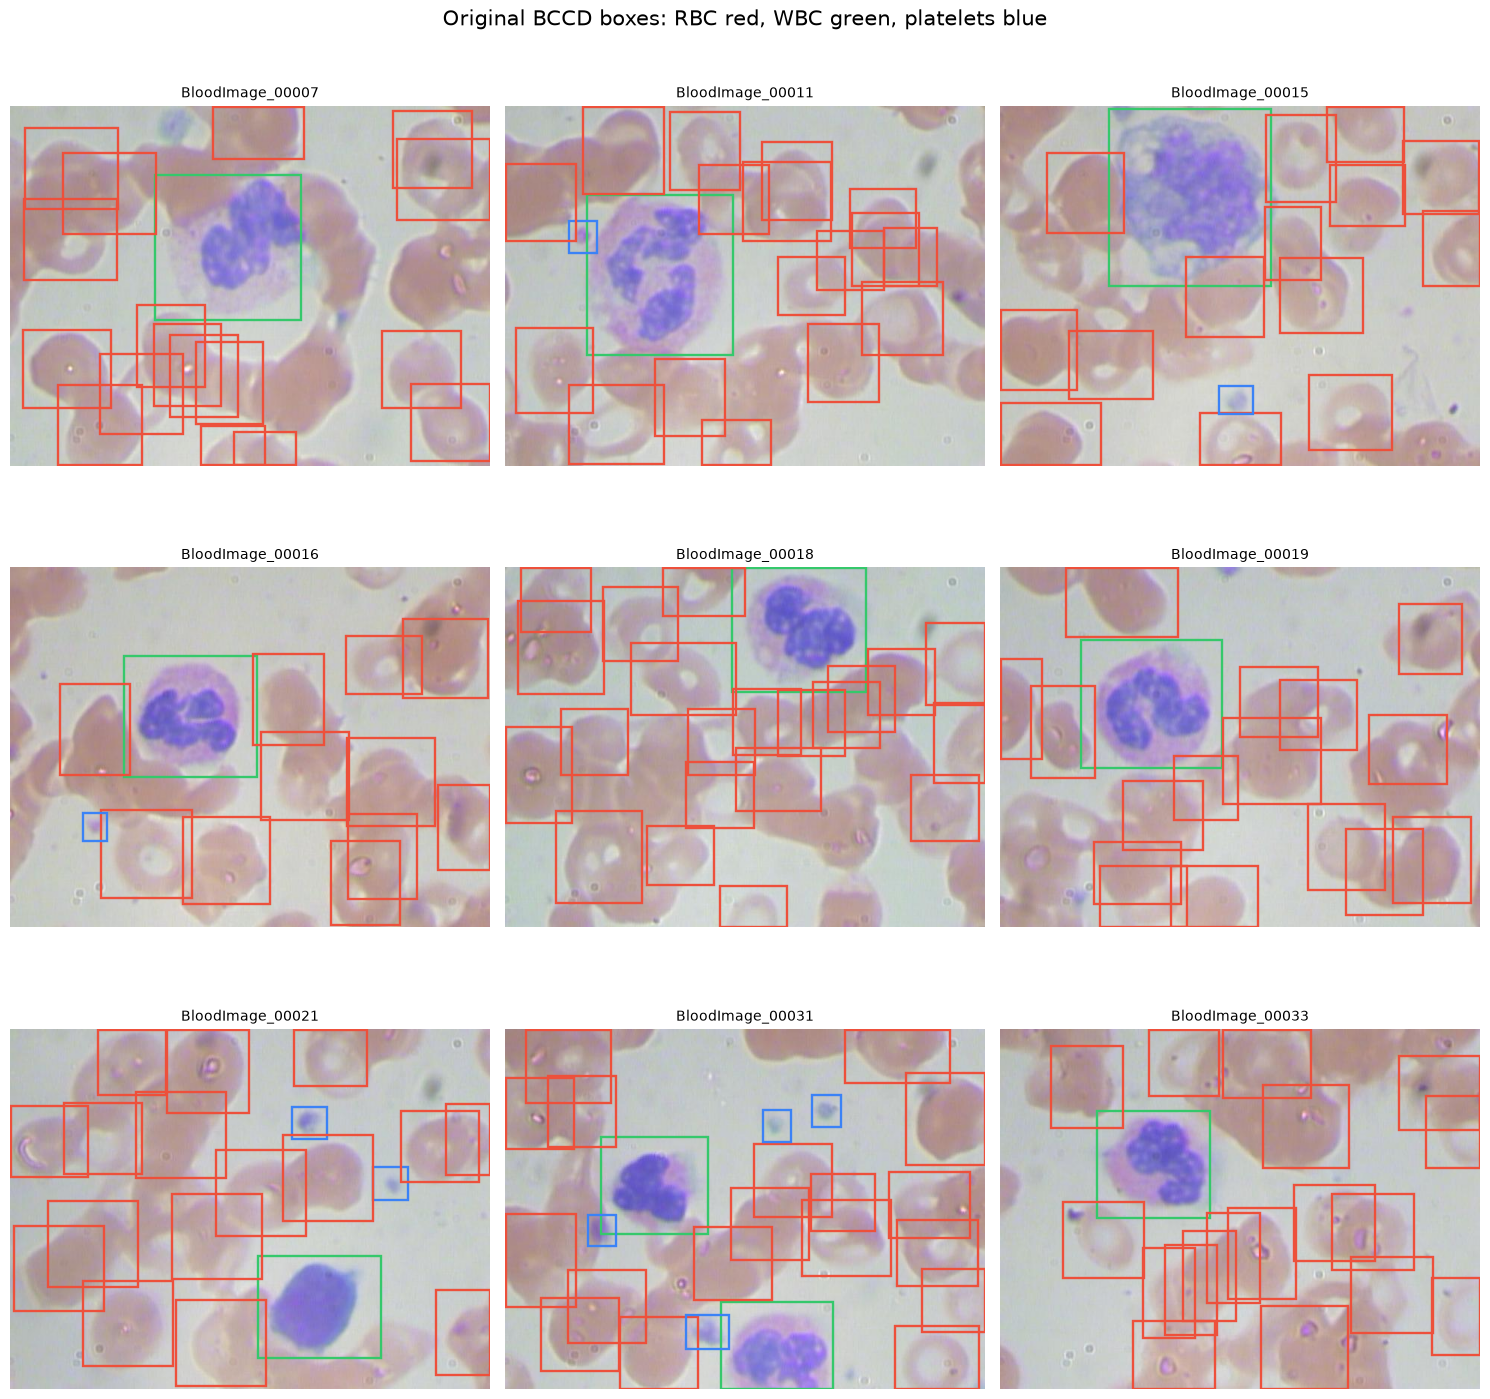

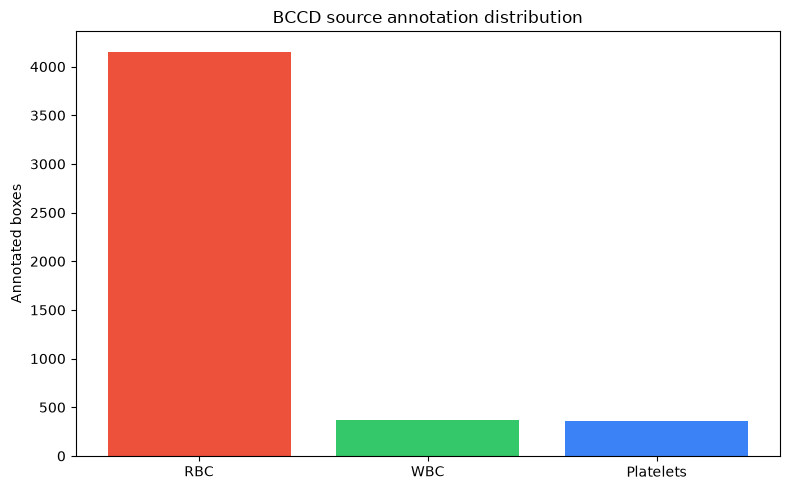

Annotation example: D:\Bcdatast\test\ann\BloodImage_00007.jpeg.json
{
    "description": "",
    "tags": [],
    "size": {
        "height": 480,
        "width": 640
    },
    "objects": [
        {
            "id": 7792866,
            "classId": 13303,
            "description": "",
            "geometryType": "rectangle",
            "labelerLogin": "gr@datasetninja.com",
            "createdAt": "2023-06-22T21:04:02.827Z",
            "updatedAt": "2023-06-22T21:04:02.827Z",
            "tags": [],
            "classTitle": "WBC",
            "points": {
                "exterior": [
                    [
                        193,
                        92
                    ],
                    [
                        387,
                        285
                    ]
                ],
                "interior": []
            }
        },
        {
            "id": 7792865,
            "classId": 13302,
            "description": "",
            "geometryType":

,source_split,image,pixels,annotation_size,clipped_boxes
0,test,BloodImage_00007,640x480,"[640, 480]",0
1,test,BloodImage_00011,640x480,"[640, 480]",0
2,test,BloodImage_00015,640x480,"[640, 480]",0
3,test,BloodImage_00016,640x480,"[640, 480]",0
4,test,BloodImage_00018,640x480,"[640, 480]",0
5,test,BloodImage_00019,640x480,"[640, 480]",0
6,test,BloodImage_00021,640x480,"[640, 480]",0
7,test,BloodImage_00031,640x480,"[640, 480]",0
8,test,BloodImage_00033,640x480,"[640, 480]",0
9,test,BloodImage_00041,640x480,"[640, 480]",0


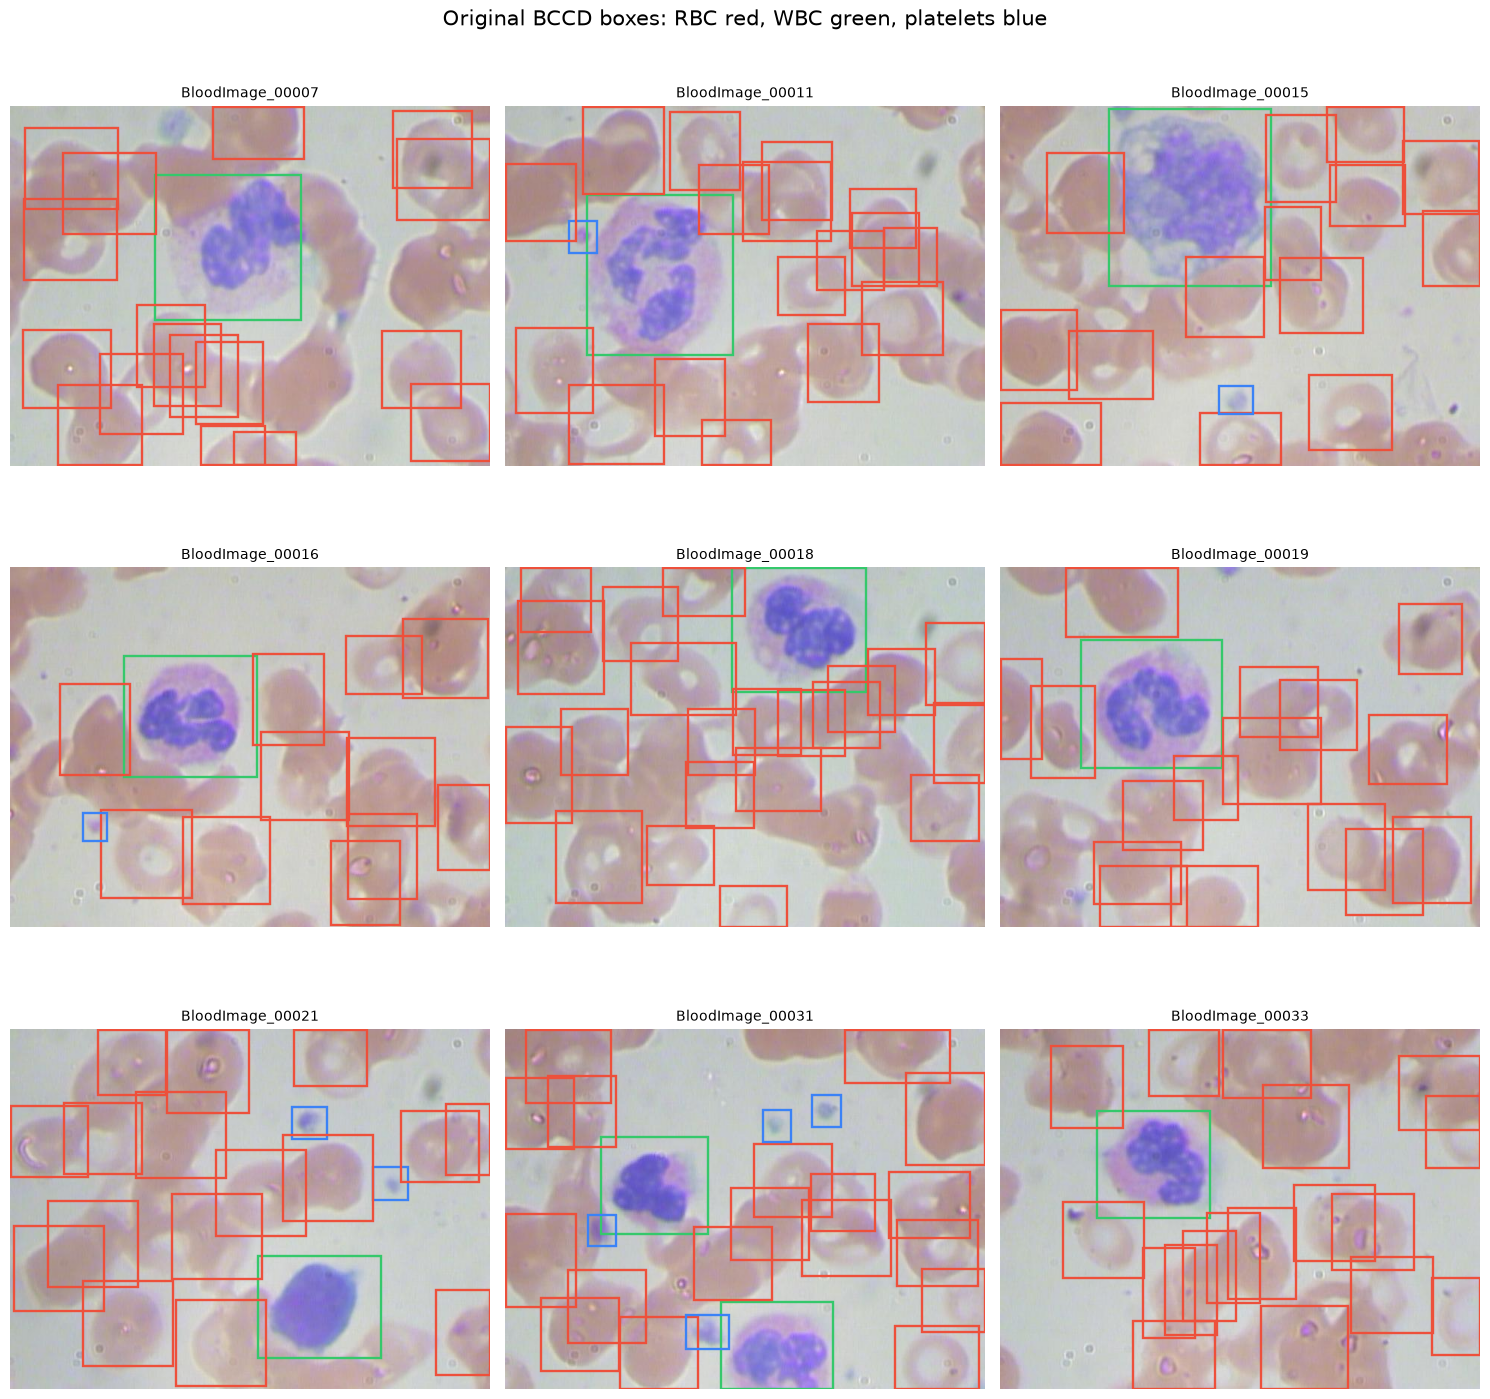

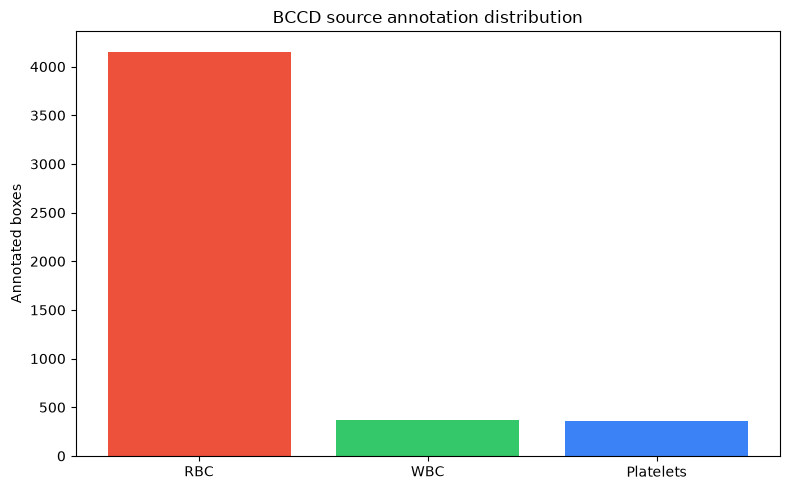

In [3]:
from src.visualization import source_gallery, class_chart
if inspection["records"]:
    display(source_gallery(inspection["records"], out / "figures" / "original_bccd_examples.png", count=9))
    display(class_chart(inspection["raw_class_distribution"], out / "figures" / "source_class_counts.png"))
    annotation_example = Path(inspection["records"][0]["annotation"])
    print("Annotation example:", annotation_example)
    print(annotation_example.read_text(encoding="utf-8")[:1800])
    display(pd.DataFrame([{"source_split": r["source_split"], "image": r["id"],
                           "pixels": f"{r['width']}x{r['height']}",
                           "annotation_size": r["annotation_size"], "clipped_boxes": len(r["clipping"])}
                          for r in inspection["records"][:10]]))

## 4. Integrity gate

Stop here if an image, annotation or bounding box is missing or unreadable.

In [4]:
assert inspection["ready"], "FAIL — source integrity errors; inspect outputs/dataset_inspection.json"
print("PASS — source inspection complete. Next: notebook 02.")

PASS — source inspection complete. Next: notebook 02.


## Next notebook

Open **02_BCCD_Preprocessing.ipynb**.